In [15]:
import time
from typing import NamedTuple, Any
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.python.solutions import face_detection
import wespeakerruntime as wespeaker
from os import listdir, path
import pyaudio
import wave
from io import BytesIO

test_subject_folder = "./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/John_Negroponte"
test_subject2_folder = "./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/Zhu_Rongji"
audio_path = r'data/LibriSpeech/train-clean-100'

audio_files = []

for user_id in listdir(audio_path):
    if path.isdir(path.join(audio_path, user_id)):
        audio_files.append([])
        for chapter in listdir(path.join(audio_path, user_id)):
            if path.isdir(path.join(audio_path, user_id, chapter)):
                for file in listdir(path.join(audio_path, user_id, chapter)):
                    if file.endswith('.flac'):
                        audio_files[-1].append(path.join(audio_path, user_id, chapter, file))

audio_files

[['data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0049.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0023.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0036.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0006.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0043.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0009.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0048.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0015.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0020.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0022.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0001.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0026.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0021.flac',
  'data/LibriSpeech/train-clean-100/5463/39174/5463-39174-0037.flac',
  'data/LibriSpeech/

In [16]:
from deepface import DeepFace
from sklearn.metrics.pairwise import cosine_similarity
import sqlite3
from typing import IO, Sequence, Any, Union, Tuple, Mapping
from numpy.typing import NDArray
from abc import ABC, abstractmethod
from concurrent.futures import ThreadPoolExecutor, as_completed
import torch
from io import BytesIO

class VerificationMethod(ABC):
    @abstractmethod
    def verify(self, data: Union[str, NDArray[Any], IO[bytes], Sequence[Union[str, NDArray[Any], IO[bytes]]]], centroids: Sequence[Tuple[int, NDArray[Any]]]) -> Sequence[Tuple[int, float]]:
        pass
    
    @abstractmethod
    def enroll_user(self, examples: Sequence[Union[str, NDArray[Any], IO[bytes]]]) -> NDArray[Any]:
        pass

class FaceVerification(VerificationMethod):
    def __init__(self, model_name: str = None):
        self.model_name = model_name
    
    def verify(self, data: Union[str, NDArray[Any], IO[bytes]], centroids: Sequence[Tuple[int, NDArray[Any]]]) -> Sequence[Tuple[int, float]]:
        target_embedding = DeepFace.represent(img_path=data, model_name=self.model_name, detector_backend='skip')[0]["embedding"]
        user_scores = []
        for user_id, embedding_blob in centroids:
            enrolled_embedding = np.frombuffer(embedding_blob, dtype=np.float32)
            similarity = ((cosine_similarity([target_embedding], [enrolled_embedding]) + 1) / 2)[0][0]
            user_scores.append((user_id, similarity))
        return sorted(user_scores, key=lambda x: x[1], reverse=True)[:5]
    
    #def enroll_user(self, examples: Sequence[Union[str, NDArray[Any], IO[bytes]]]) -> NDArray[Any]:
    #    embeddings = []
    #    for example in examples:
    #        embedding = DeepFace.represent(img_path=example, model_name=self.model_name, detector_backend='skip')[0]["embedding"]
    #        embeddings.append(embedding)
    #    centroid = np.mean(embeddings, axis=0)
    #    return centroid
    
    def enroll_user(self, examples: Sequence[Union[str, NDArray[Any], IO[bytes]]]) -> NDArray[Any]:
        embedding = DeepFace.represent(img_path=examples, model_name=self.model_name, detector_backend='skip')
        embeddings = [entry[0]["embedding"] for entry in embedding]
        centroid = np.mean(embeddings, axis=0)
        return centroid
    
class VoiceVerification(VerificationMethod):
    def __init__(self, lang: str = "en"):
        self.lang = lang
        self.spk = wespeaker.Speaker(lang=lang, inter_op_num_threads=4, intra_op_num_threads=4)
        self.vad, utils = torch.hub.load(repo_or_dir='snakers4/silero-vad', model='silero_vad')
        (self.get_speech_timestamps, _, self.read_audio, _, _) = utils
    
    def verify(self, data: Union[str, NDArray[Any], IO[bytes]], centroids: Sequence[Tuple[int, NDArray[Any]]]) -> Sequence[Tuple[int, float]]:
        speech_length_ok, total_speech_duration = self._check_audio_length(data)
        print(f"Total speech duration: {total_speech_duration:.2f} seconds")
        if not speech_length_ok:
            return []
        if isinstance(data, BytesIO):
            data.seek(0)

        target_embedding = self.spk.extract_embedding(data)[0, :]
        user_scores = []
        for user_id, embedding_blob in centroids:
            enrolled_embedding = np.frombuffer(embedding_blob, dtype=np.float32)
            similarity = ((cosine_similarity([target_embedding], [enrolled_embedding]) + 1) / 2)[0][0]
            user_scores.append((user_id, similarity))
        return sorted(user_scores, key=lambda x: x[1], reverse=True)[:5]
    
    def enroll_user(self, examples: Sequence[Union[str, NDArray[Any], IO[bytes]]]) -> NDArray[Any]:
        embeddings = []
        for example in examples:
            speech_length_ok, total_speech_duration = self._check_audio_length(example)
            if isinstance(example, BytesIO):
                example.seek(0)
            if not speech_length_ok:
                continue
            embedding = self.spk.extract_embedding(example)[0, :]
            embeddings.append(embedding)
        centroid = np.mean(embeddings, axis=0)
        return centroid
    
    def _check_audio_length(self, audio_data: Union[str, NDArray[Any], IO[bytes]], threshold: float = 2.5) -> Tuple[bool, float]:
        if isinstance(audio_data, str) or isinstance(audio_data, BytesIO):
            audio_data = self.read_audio(audio_data, sampling_rate=16000)
        speech_timestamps = self.get_speech_timestamps(torch.tensor(audio_data), self.vad, return_seconds=True)
        print(f"Detected speech segments: {speech_timestamps}")
        total_speech_duration = sum(subset['end'] - subset['start'] for subset in speech_timestamps)
        return total_speech_duration >= threshold, total_speech_duration

class VerificationManager:
    def __init__(self, methods: Mapping[str, VerificationMethod], enrolled_users_db_name: str = 'enrolled_users.db'):
        self.methods = methods
        self.enrolled_users_db = sqlite3.connect(enrolled_users_db_name)
        self.cursor = self.enrolled_users_db.cursor()
        is_empty = self.cursor.execute("SELECT name FROM sqlite_master WHERE type='table' AND name='users';").fetchone() is None
        if is_empty:
            self.cursor.execute(f'''CREATE TABLE users
                                   (id INTEGER PRIMARY KEY AUTOINCREMENT,
                                    name TEXT NOT NULL UNIQUE,
                                    {' BLOB NOT NULL,'.join(self.methods.keys())} BLOB NOT NULL);''')
            self.enrolled_users_db.commit()
    
    #def enroll_user(self, name: str, examples: Mapping[str, Sequence[Union[str, NDArray[Any], IO[bytes]]]]) -> None:
    #    centroid_embeddings = {}
    #    for method_name, method in self.methods.items():
    #        centroid = method.enroll_user(examples[method_name])
    #        centroid_embeddings[method_name] = centroid.astype(np.float32).tobytes()
    #    placeholders = ', '.join('?' * (len(centroid_embeddings) + 1))
    #    columns = ', '.join(['name'] + list(centroid_embeddings.keys()))
    #    values = [name] + list(centroid_embeddings.values())
    #    self.cursor.execute(f'INSERT INTO users ({columns}) VALUES ({placeholders});', values)
    #    self.enrolled_users_db.commit()
    
    def enroll_user(self, name: str, examples: Mapping[str, Sequence[Union[str, NDArray[Any], IO[bytes]]]]) -> None:
        # 1) run embedding extraction in parallel
        def run_method(method_name: str):
            method = self.methods[method_name]
            centroid = method.enroll_user(examples[method_name])  # heavy work
            return method_name, centroid.astype(np.float32).tobytes()

        centroid_embeddings = {}
        with ThreadPoolExecutor(max_workers=min(2, len(self.methods))) as ex:
            for method_name, blob in ex.map(run_method, self.methods.keys()):
                centroid_embeddings[method_name] = blob

        # 2) single DB write (main thread)
        columns = ", ".join(["name"] + list(centroid_embeddings.keys()))
        placeholders = ", ".join(["?"] * (1 + len(centroid_embeddings)))
        values = [name] + [centroid_embeddings[k] for k in centroid_embeddings.keys()]

        self.cursor.execute(f"INSERT INTO users ({columns}) VALUES ({placeholders});", values)
        self.enrolled_users_db.commit()
        
    
    #def verify(self, data: Mapping[str, Union[str, NDArray[Any], IO[bytes], Sequence[Union[str, NDArray[Any], IO[bytes]]]]]) -> Mapping[str, Tuple[int, str, float]]:
    #    best_users = {}
    #    for method_name, method in self.methods.items():
    #        self.cursor.execute(f'SELECT id, {method_name} FROM users;')
    #        centroids = self.cursor.fetchall()
    #        best_users_list = method.verify(data[method_name], centroids)
    #        best_users[method_name] = [(user_id, self.cursor.execute(f'SELECT name FROM users WHERE id = ?;', (user_id,)).fetchone()[0], score) for user_id, score in best_users_list]
    #
    #    return self._combine_scores(best_users)
    
    def verify(self, data: Mapping[str, Union[str, NDArray[Any], IO[bytes], Sequence[Union[str, NDArray[Any], IO[bytes]]]]]) -> Mapping[str, Tuple[int, str, float]]:
        id_to_name = dict(self.cursor.execute("SELECT id, name FROM users;").fetchall())

        centroids_by_method = {}
        for method_name in self.methods.keys():
            rows = self.cursor.execute(f"SELECT id, {method_name} FROM users;").fetchall()
            centroids_by_method[method_name] = rows

        def run_method(method_name: str):
            method = self.methods[method_name]
            centroids = centroids_by_method[method_name]
            best_users_list = method.verify(data[method_name], centroids)

            return method_name, [(uid, id_to_name.get(uid, "<unknown>"), score) for uid, score in best_users_list]

        best_users = {}
        max_workers = min(len(self.methods), 4)
        with ThreadPoolExecutor(max_workers=max_workers) as ex:
            futures = [ex.submit(run_method, name) for name in self.methods.keys()]
            for fut in as_completed(futures):
                method_name, result = fut.result()
                best_users[method_name] = result

        return self._combine_scores(best_users)
    
    def _combine_scores(self, best_users: Mapping[str, Sequence[Tuple[int, str, float]]]) -> Union[Mapping[str, Tuple[int, str, float]], Mapping[str, str]]:
        voice_threshold = 0.7
        face_threshold = 0.84
        alpha_voice = 0.3
        interpolation_weight = 0.85

        if len(best_users['voice_verification']) == 0:
            return {'result': 'reject', 'reason': 'not enough speech detected'}

        if best_users['voice_verification'][0][2] < voice_threshold:
            return {'result': 'reject', 'reason': 'voice verification below threshold'}
        
        best_voice_user_id, best_voice_user_name, best_voice_score = best_users['voice_verification'][0]

        delta_best_voice = best_voice_score - best_users['voice_verification'][1][2]

        voice_confidence = min(1.0, best_voice_score + alpha_voice * delta_best_voice)

        if not best_voice_user_id in list(map(lambda entry: entry[0], best_users['face_verification'])):
            return {'result': 'reject', 'reason': 'best voice match not in face verification results'}
        
        face_user_id, face_user_name, face_score = next(filter(lambda entry: entry[0] == best_voice_user_id, best_users['face_verification']))

        clipped_face_confidence = np.clip(face_score / face_threshold, 0, 1)

        return {'result': 'accept' if voice_confidence * interpolation_weight + clipped_face_confidence * (1 - interpolation_weight) >= 0.5 else 'reject',
                'voice_match': (best_voice_user_id, best_voice_user_name, best_voice_score),
                'face_match': (face_user_id, face_user_name, face_score),
                'combined_score': voice_confidence * interpolation_weight + clipped_face_confidence * (1 - interpolation_weight)}



fv_model = FaceVerification(model_name='Facenet512')
#fv_model.enroll_user('test_user', map(lambda img_name: path.join(test_subject_folder, img_name), listdir(test_subject_folder)[:30]))
#fv_model.enroll_user('test_user2', map(lambda img_name: path.join(test_subject2_folder, img_name), listdir(test_subject2_folder)[:30]))
#fv_model.verify(cv2.imread(path.join(test_subject2_folder, listdir(test_subject2_folder)[6])))

spk = wespeaker.Speaker(lang="en")


#manager.enroll_user('Lleyton_Hewitt', {'face_verification': list(map(lambda img_name: path.join(test_subject_folder, img_name), listdir(test_subject_folder)[:30]))})
#manager.enroll_user('Zhu_Rongji', {'face_verification': list(map(lambda img_name: path.join(test_subject2_folder, img_name), listdir(test_subject2_folder)[:30]))})
#manager.verify(cv2.imread(path.join(test_subject2_folder, listdir(test_subject2_folder)[6])))

manager = VerificationManager(methods={'face_verification': fv_model, 'voice_verification': VoiceVerification(lang='en')})

#images = listdir(path.join("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/", 'John_Negroponte'))
#DeepFace.represent(list(map(lambda img_name: path.join("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/", 'John_Negroponte', img_name), images[:20])), model_name='Facenet512', detector_backend='skip')[0][0]["embedding"]

Using cache found in /home/alexd/.cache/torch/hub/snakers4_silero-vad_master


In [6]:
cnt = 0

matches = {}

for folder in listdir("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/"):
    images = listdir(path.join("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/", folder))
    if len(images) > 20:
        manager.enroll_user(folder, {
            'face_verification': list(map(lambda img_name: path.join("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/", folder, img_name), images[:20])),
            'voice_verification': audio_files[cnt][:5]
        })
        matches[folder] = audio_files[cnt]
        cnt+=1

In [60]:
manager.verify({
    'face_verification': cv2.imread(path.join(test_subject_folder, listdir(test_subject_folder)[6])),
    'voice_verification': matches['John_Negroponte'][6]})

{'result': 'accept',
 'voice_match': (5, 'John_Negroponte', np.float32(0.93181634)),
 'face_match': (5, 'John_Negroponte', np.float64(0.7102470247297503)),
 'combined_score': np.float64(0.9768298258445982)}

In [59]:
user_name = 'Vladimir_Putin'

manager.verify({
    'face_verification': cv2.imread(path.join(f'./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/{user_name}', listdir(f'./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/{user_name}')[6])),
    'voice_verification': matches[user_name][6]})

{'result': 'accept',
 'voice_match': (12, 'Vladimir_Putin', np.float32(0.90164906)),
 'face_match': (12, 'Vladimir_Putin', np.float64(0.6643336059101982)),
 'combined_score': np.float64(0.9294756012560457)}

In [49]:
results = {}
corrects_face = []
corrects_voice = []
wrongs_face = []
wrongs_voice = []

for user in matches.keys():
    print(f"Verifying {user}")
    result = manager.verify({
        'face_verification': cv2.imread(path.join("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/", user, listdir(path.join("./data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/", user))[6])),
        'voice_verification': matches[user][-6]
    })
    results[user] = result
    if result['face_verification'][0][1] == user:
        corrects_face.append(result['face_verification'][0][2])
    else:
        wrongs_face.append(result['face_verification'][0][2])
    if result['voice_verification'][0][1] == user:
        corrects_voice.append(result['voice_verification'][0][2])
    else:
        wrongs_voice.append(result['voice_verification'][0][2])
results

Verifying Jennifer_Aniston


KeyError: 'face_verification'

In [166]:
matches

{'Jennifer_Aniston': ['data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0000.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0041.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0016.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0036.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0020.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0021.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0037.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0017.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0040.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0001.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0030.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0026.flac',
  'data/LibriSpeech/train-clean-100/1069/133709/1069-133709-0006.flac',
  'data/LibriSpeech/train-clean-100/1069/133

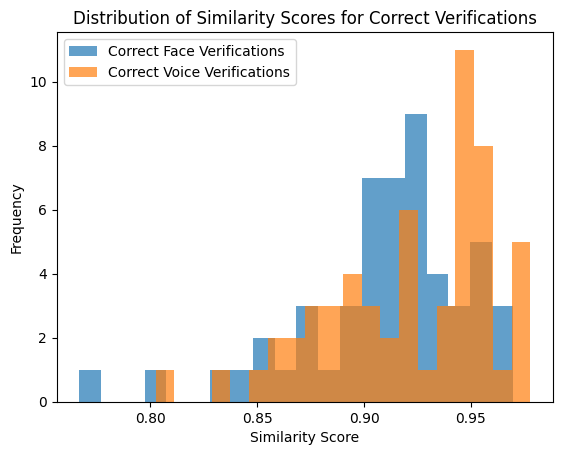

In [193]:
#plot face correct score distribution
import matplotlib.pyplot as plt

plt.hist(corrects_face, bins=20, alpha=0.7, label='Correct Face Verifications')
plt.hist(corrects_voice, bins=20, alpha=0.7, label='Correct Voice Verifications')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.title('Distribution of Similarity Scores for Correct Verifications')
plt.legend()
plt.show()

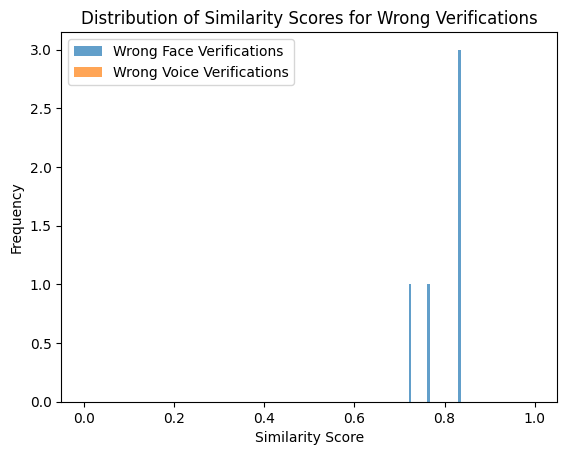

[]

In [199]:
plt.hist(wrongs_face, bins=20, alpha=0.7, label='Wrong Face Verifications')
plt.hist(wrongs_voice, bins=20, alpha=0.7, label='Wrong Voice Verifications')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.title('Distribution of Similarity Scores for Wrong Verifications')
plt.legend()
plt.show()

wrongs_voice

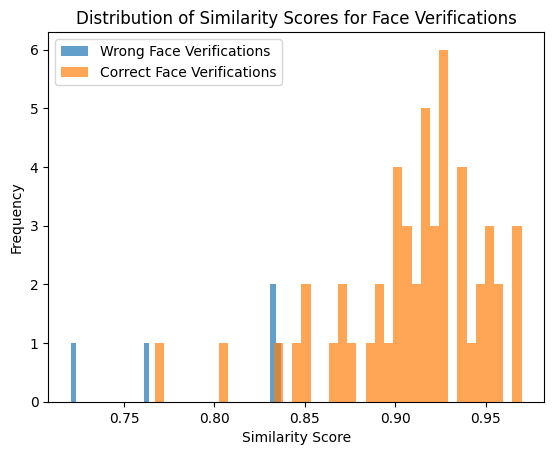

In [195]:
plt.hist(wrongs_face, bins=40, alpha=0.7, label='Wrong Face Verifications')
plt.hist(corrects_face, bins=40, alpha=0.7, label='Correct Face Verifications')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.title('Distribution of Similarity Scores for Face Verifications')
plt.legend()
plt.show()

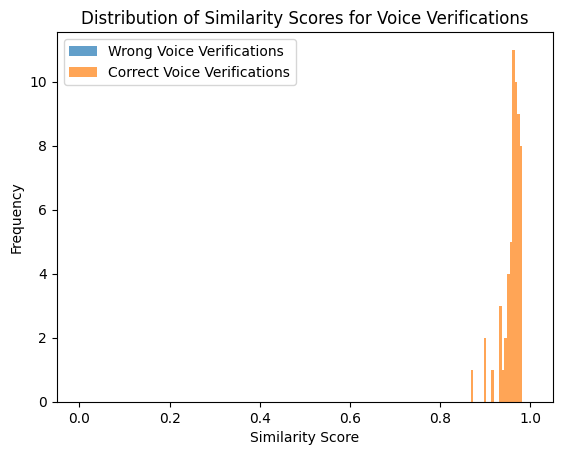

In [186]:
plt.hist(wrongs_voice, bins=20, alpha=0.7, label='Wrong Voice Verifications')
plt.hist(corrects_voice, bins=20, alpha=0.7, label='Correct Voice Verifications')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.title('Distribution of Similarity Scores for Voice Verifications')
plt.legend()
plt.show()

In [57]:
manager.verify({
    'face_verification': cv2.imread("data/LFW Dataset/lfw-deepfunneled/lfw-deepfunneled/Aaron_Tippin/Aaron_Tippin_0001.jpg"),
    'voice_verification': "data/LibriSpeech/train-clean-100/198/126831/198-126831-0006.flac"})

{'result': 'reject',
 'reason': 'best voice match not in face verification results'}

In [58]:
conn = sqlite3.connect('enrolled_users.db')
cursor = conn.cursor()
fv_model.verify(cv2.imread(path.join(test_subject_folder, listdir(test_subject_folder)[6])), cursor.execute('SELECT id, face_verification FROM users WHERE name=?;', ('John_Negroponte',)).fetchall())

[(5, np.float64(0.7102470247297503))]

In [17]:
class BoundingBox(NamedTuple):
    xmin: float
    ymin: float
    width: float
    height: float

class KeyPoint(NamedTuple):
    x: float
    y: float

class LocationData(NamedTuple):
    relative_bounding_box: BoundingBox
    relative_keypoints: list[KeyPoint]

class Detection(NamedTuple):
    label_id: int
    score: list[float]
    location_data: LocationData

class DetectionResults(NamedTuple):
    detections: list[Detection]

def rotate_and_crop(frame_bgr, bbox, left_eye, right_eye, out_size=112, margin=0.25):
    h, w = frame_bgr.shape[:2]
    x, y, bw, bh = bbox

    cx, cy = x + bw/2, y + bh/2
    size = max(bw, bh) * (1.0 + margin)

    x1 = int(max(0, cx - size/2))
    y1 = int(max(0, cy - size/2))
    x2 = int(min(w, cx + size/2))
    y2 = int(min(h, cy + size/2))

    crop = frame_bgr[y1:y2, x1:x2]
    if crop.size == 0:
        return None

    lx, ly = left_eye
    rx, ry = right_eye
    angle = np.degrees(np.arctan2((ry - ly), (rx - lx)))

    ch, cw = crop.shape[:2]
    M = cv2.getRotationMatrix2D((cw/2, ch/2), angle, 1.0)
    rotated = cv2.warpAffine(crop, M, (cw, ch), flags=cv2.INTER_LINEAR)

    return cv2.resize(rotated, (out_size, out_size), interpolation=cv2.INTER_LINEAR)



def detect_bbox_and_eyes(frame_bgr: cv2.typing.MatLike, detector: face_detection.FaceDetection, min_conf=0.6):
    h, w = frame_bgr.shape[:2]
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    res: DetectionResults = DetectionResults(detections=detector.process(rgb).detections)

    if not res.detections:
        return None

    best = max(res.detections, key=lambda d: d.score[0])
    if best.score[0] < min_conf:
        return None

    #print(list(map(lambda d: (d.label_id, d.score), res.detections)))

    bb = best.location_data.relative_bounding_box
    x = int(bb.xmin * w)
    y = int(bb.ymin * h)
    bw = int(bb.width * w)
    bh = int(bb.height * h)

    # keypoints: right_eye, left_eye, nose, mouth, right_ear, left_ear
    kps = best.location_data.relative_keypoints
    right_eye = (int(kps[0].x * w), int(kps[0].y * h))
    left_eye  = (int(kps[1].x * w), int(kps[1].y * h))

    return (x, y, bw, bh), left_eye, right_eye, best.score[0]
        

In [18]:
CHUNK = 1024
FORMAT = pyaudio.paInt16
CHANNELS = 1
RATE = 16000
RECORD_SECONDS = 5
WAVE_OUTPUT_FILENAME = "output.wav"

p = pyaudio.PyAudio()

stream = p.open(format=FORMAT,
                channels=CHANNELS,
                rate=RATE,
                input=True,
                frames_per_buffer=CHUNK)

print("* recording")

frames = []
best_face = None

cap = cv2.VideoCapture("/dev/video0", cv2.CAP_V4L2)
print("cap opened:", cap.isOpened())
if not cap.isOpened():
    raise RuntimeError("Failed to open /dev/video0")

cap.set(cv2.CAP_PROP_FPS, 30)

print("backend:", cap.getBackendName())
print("fourcc:", int(cap.get(cv2.CAP_PROP_FOURCC)))
print("size:", cap.get(cv2.CAP_PROP_FRAME_WIDTH), cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print("fps:", cap.get(cv2.CAP_PROP_FPS))
with face_detection.FaceDetection(model_selection=0, min_detection_confidence=0.6) as detector:
    previous_time = time.time() * 1000
    fps = 0.0
    best_score = 0.0
    start = time.time()
    total_time = 0.0

    while time.time() - start < RECORD_SECONDS:
        data = stream.read(CHUNK, exception_on_overflow=False)
        frames.append(data)

        ok, frame = cap.read()
        if not ok:
            break

        out = detect_bbox_and_eyes(frame, detector)
        if out is not None:
            bbox, left_eye, right_eye, score = out
            face112 = rotate_and_crop(frame, bbox, left_eye, right_eye, margin=0.9, out_size=512)
            if face112 is not None and score > best_score:
                best_face = cv2.flip(cv2.flip(face112, 0), 1)
                best_score = score
                #cv2.imshow("face112", best_face)
                cv2.imwrite("best_face5.jpg", best_face)
                print("Saved best_face.jpg with score:", best_score)

        #cv2.imshow("cam", frame)

        current_time = time.time() * 1000
        elapsed_time = current_time - previous_time
        previous_time = current_time
        total_time += elapsed_time

        fps = 1000.0 / elapsed_time if elapsed_time > 0 else 0.0
        print(f"Current FPS: {fps:.2f}, Best Score: {best_score:.4f}, Total Time: {total_time/1000:.2f}s", end='\r')

        #cv2.setWindowTitle("cam", f"cam - FPS: {fps:.2f}, Best Score: {best_score:.2f}")

        #if cv2.waitKey(1) & 0xFF == 27:
        #    break

cap.release()
#cv2.destroyAllWindows()

print("* done recording")

stream.stop_stream()
stream.close()
sampwidth = p.get_sample_size(FORMAT)
p.terminate()

* recording
cap opened: True
backend: V4L2
fourcc: 1448695129
size: 640.0 480.0
fps: 30.0
Saved best_face.jpg with score: 0.6133913993835449: 4.07s
Saved best_face.jpg with score: 0.6211771965026855: 4.25s
Saved best_face.jpg with score: 0.653890073299408e: 4.34s
Saved best_face.jpg with score: 0.6831865906715393: 4.59s
* done recording63, Best Score: 0.6832, Total Time: 5.01s


In [19]:
file_in_memory = BytesIO()

# Write a proper WAV into RAM (closing finalizes the header)
with wave.open(file_in_memory, "wb") as wf:
    wf.setnchannels(CHANNELS)
    wf.setsampwidth(sampwidth)
    wf.setframerate(RATE)
    wf.writeframes(b"".join(frames))

# Rewind again because torchaudio.load consumed the stream
file_in_memory.seek(0)

#emb = spk.extract_embedding(file_in_memory)
#emb.shape

manager.verify({
    'face_verification': best_face,
    'voice_verification': file_in_memory
})

Detected speech segments: [{'start': 0.2, 'end': 1.1}, {'start': 1.3, 'end': 3.7}, {'start': 3.9, 'end': 5.184}]
Total speech duration: 4.58 seconds


{'result': 'reject', 'reason': 'voice verification below threshold'}

In [7]:
local_images = './data/Local/images/'

local_images_file_paths = [path.join(local_images, img_name) for img_name in listdir(local_images)]

file_in_memory.seek(0)

manager.enroll_user('pagura', {
    'face_verification': local_images_file_paths,
    'voice_verification': [file_in_memory]
})

In [13]:
file_in_memory.seek(0)

manager.verify({
    'face_verification': best_face,
    'voice_verification': file_in_memory
})

{'result': 'reject',
 'reason': 'best voice match not in face verification results'}

In [12]:
import sqlite3

conn = sqlite3.connect('enrolled_users.db')
cursor = conn.cursor()

cursor.execute('DELETE FROM users WHERE name=?;', ('qoiureouruour',))
conn.commit()

In [ ]:
cap = cv2.VideoCapture("/dev/video0", cv2.CAP_V4L2)
print("cap opened:", cap.isOpened())
if not cap.isOpened():
    raise RuntimeError("Failed to open /dev/video0")


print("backend:", cap.getBackendName())
print("fourcc:", int(cap.get(cv2.CAP_PROP_FOURCC)))
print("size:", cap.get(cv2.CAP_PROP_FRAME_WIDTH), cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print("fps:", cap.get(cv2.CAP_PROP_FPS))

In [ ]:
import queue

tqueue = queue.Queue(maxsize=2)

tqueue.put(5, block=False)
tqueue.put(6, block=False)
try:
    tqueue.put(7, block=False)
except queue.Full:
    tqueue.get()
    tqueue.put(7, block=False)
tqueue.task_done()

In [ ]:
from sortedcontainers import SortedList

slist = SortedList()

slist.add((0.8, "image1.jpg"))
slist.add((0.9, "image2.jpg"))
slist.add((0.85, "image3.jpg"))

slist

SortedList([(0.8, 'image1.jpg'), (0.85, 'image3.jpg'), (0.9, 'image2.jpg')])